In [3]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')


In [4]:
df = pd.read_csv("/content/titanic.csv")

In [5]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,0,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,1,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,0,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,0,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,1,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [7]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  
 1   Survived     418 non-null    int64  
 2   Pclass       418 non-null    int64  
 3   Name         418 non-null    object 
 4   Sex          418 non-null    object 
 5   Age          332 non-null    float64
 6   SibSp        418 non-null    int64  
 7   Parch        418 non-null    int64  
 8   Ticket       418 non-null    object 
 9   Fare         417 non-null    float64
 10  Cabin        91 non-null     object 
 11  Embarked     418 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 39.3+ KB


In [8]:
df.info()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  
 1   Survived     418 non-null    int64  
 2   Pclass       418 non-null    int64  
 3   Name         418 non-null    object 
 4   Sex          418 non-null    object 
 5   Age          332 non-null    float64
 6   SibSp        418 non-null    int64  
 7   Parch        418 non-null    int64  
 8   Ticket       418 non-null    object 
 9   Fare         417 non-null    float64
 10  Cabin        91 non-null     object 
 11  Embarked     418 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 39.3+ KB


In [9]:
df.describe(include='object')


,Name,Sex,Ticket,Cabin,Embarked
count,418,418,418,91,418
unique,418,2,363,76,3
top,"Peter, Master. Michael J",male,PC 17608,B57 B59 B63 B66,S
freq,1,266,5,3,270


In [10]:
df.columns


Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

In [11]:
df.tail()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
413,1305,0,3,"Spector, Mr. Woolf",male,NaN,0,0,A.5. 3236,8.0500,NaN,S
414,1306,1,1,"Oliva y Ocana, Dona. Fermina",female,39.0,0,0,PC 17758,108.9000,C105,C
415,1307,0,3,"Saether, Mr. Simon Sivertsen",male,38.5,0,0,SOTON/O.Q. 3101262,7.2500,NaN,S
416,1308,0,3,"Ware, Mr. Frederick",male,NaN,0,0,359309,8.0500,NaN,S
417,1309,0,3,"Peter, Master. Michael J",male,NaN,1,1,2668,22.3583,NaN,C


In [12]:
df.isnull().sum()


,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,86
SibSp,0
Parch,0
Ticket,0
Fare,1


In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Fare'] = df['Fare'].fillna(df['Fare'].median())
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])
df['Has_Cabin'] = df['Cabin'].notnull().astype(int)
df.drop(columns=['Cabin', 'Ticket'], inplace=True)
df.drop_duplicates(inplace=True)

In [15]:
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
df['IsAlone'] = (df['FamilySize'] == 1).astype(int)
df['Title'] = df['Name'].str.extract(r' ([A-Za-z]+)\.')
df['AgeGroup'] = pd.cut(df['Age'], [0,12,18,60,100],
                        labels=['Child','Teen','Adult','Senior'])

In [16]:
df[df['Sex']=='female']
df[(df['Age']>30) & (df['Pclass']==1)]
df.sort_values('Fare', ascending=False).head(10)
df['Pclass'].value_counts()

,count
Pclass,
3,218
1,107
2,93


In [18]:
# Remove unnecessary columns (safe, no error if already removed)
df.drop(columns=['Cabin', 'Ticket', 'PassengerId'], inplace=True, errors='ignore')

# Fill missing values
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Fare'] = df['Fare'].fillna(df['Fare'].median())
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

# Remove duplicates
df.drop_duplicates(inplace=True)

# Check result
print(df.isnull().sum())
df.head()

Survived      0
Pclass        0
Name          0
Sex           0
Age           0
SibSp         0
Parch         0
Fare          0
Embarked      0
Has_Cabin     0
FamilySize    0
IsAlone       0
Title         0
AgeGroup      0
dtype: int64


,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Fare,Embarked,Has_Cabin,FamilySize,IsAlone,Title,AgeGroup
0,0,3,"Kelly, Mr. James",male,34.5,0,0,7.8292,Q,0,1,1,Mr,Adult
1,1,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,7.0000,S,0,2,0,Mrs,Adult
2,0,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,9.6875,Q,0,1,1,Mr,Senior
3,0,3,"Wirz, Mr. Albert",male,27.0,0,0,8.6625,S,0,1,1,Mr,Adult
4,1,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,12.2875,S,0,3,0,Mrs,Adult


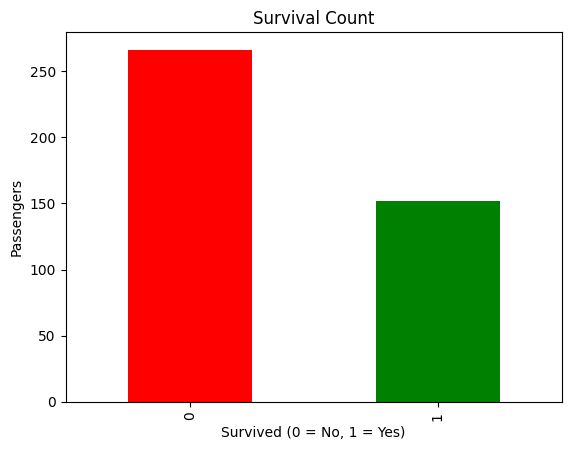

In [19]:
df['Survived'].value_counts().plot(kind='bar', color=['red','green'])
plt.title('Survival Count')
plt.xlabel('Survived (0 = No, 1 = Yes)')
plt.ylabel('Passengers')
plt.show()

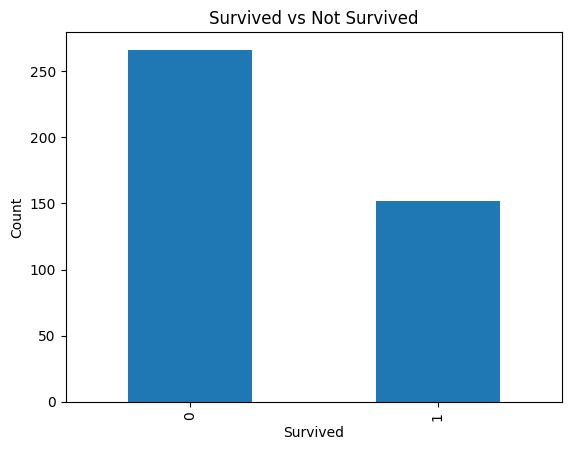

In [20]:
#  how many survived
df['Survived'].value_counts().plot(kind='bar')
plt.title('Survived vs Not Survived')
plt.xlabel('Survived')
plt.ylabel('Count')
plt.show()

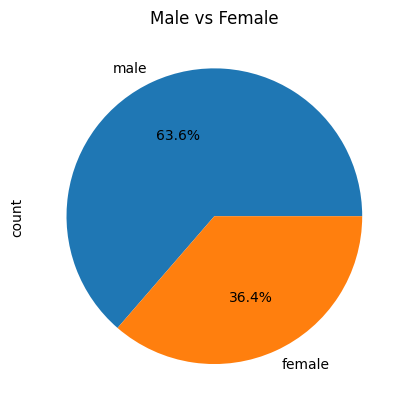

In [21]:
# male vs female
df['Sex'].value_counts().plot(kind='pie', autopct='%1.1f%%')
plt.title('Male vs Female')
plt.show()

In [22]:
raw = pd.read_csv("/content/titanic.csv")
print("Before shape:", raw.shape)
print(raw.isnull().sum())

Before shape: (418, 12)
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age             86
SibSp            0
Parch            0
Ticket           0
Fare             1
Cabin          327
Embarked         0
dtype: int64


In [23]:
clean = raw.copy()
clean.drop(columns=['Cabin', 'Ticket', 'PassengerId'], inplace=True)
clean['Age'] = clean['Age'].fillna(clean['Age'].median())
clean['Fare'] = clean['Fare'].fillna(clean['Fare'].median())
clean.drop_duplicates(inplace=True)

In [24]:
print("After shape:", clean.shape)
print(clean.isnull().sum())

After shape: (418, 9)
Survived    0
Pclass      0
Name        0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64


In [25]:
compare = pd.DataFrame({
    'Before': [raw.shape[0], raw.shape[1], raw.isnull().sum().sum()],
    'After': [clean.shape[0], clean.shape[1], clean.isnull().sum().sum()]
}, index=['Rows', 'Columns', 'Missing values'])
compare

,Before,After
Rows,418,418
Columns,12,9
Missing values,414,0


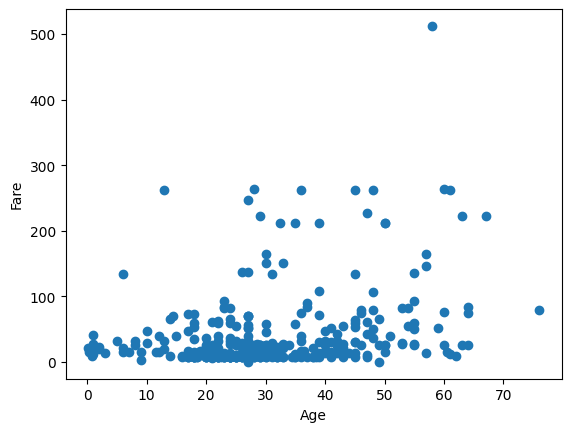

In [26]:
# 5. age and fare
plt.scatter(df['Age'], df['Fare'])
plt.xlabel('Age')
plt.ylabel('Fare')
plt.show()